# 1 — Figures

Every figure of the article and of the Supporting Information, drawn from the
shipped `values/*.csv` and `values/*.json`. Nothing is recomputed and no
quantum-chemistry stack is needed: `numpy`, `pandas` and `matplotlib` suffice.

**Part A** reproduces the seven article figures — 3, 4, 5, 6, A1, A2, A3.
**Part B** draws the supporting figures and SI Figure S4, the shot-budget study.

Images are written to `figures/output/notebook1/` (created on first run).

These cells keep the energies in **kcal/mol**, the unit of the stored files. The
article reports mHa; `figures/make_figures.py` draws the same data in mHa at the
journal print size, and is the reference figure set.

## Geometries

The six structures in clear with their bond lengths, generated from `succd/geoms.py`, so the input to every calculation below is visible without opening another file.


In [1]:
# ----------------------------------------------------------------------
# Geometries of the six systems in Angstrom, generated verbatim from
# geoms.py so that this cell cannot drift from what the pipeline reads.
# Reference only: this notebook recomputes nothing, it redraws stored values.
# To compute with an edited geometry use notebook 2, 4 or 5.
# These are the MP2/def2-SVP optimised structures of the article.
# ----------------------------------------------------------------------
GEOMETRIES = {

"H6": """H      -0.00000013033398    -0.00000027656978    -1.63585537349176
H      -0.00000002026762    -0.00000001049860    -0.88216228307366
H       0.00000005145092     0.00000026737096     2.12317470217342
H       0.00000019741506     0.00000028652252     2.87682413358394
H       0.00000001191796     0.00000000445340     5.88216389396856
H      -0.00000011018233    -0.00000027127849     6.63585492683949""",

"H8": """H       0.00000014047129     0.00000007179489    -2.49463655320066
H       0.00000005471022     0.00000003978284    -1.74094036515667
H      -0.00000000410940    -0.00000006874485     1.24863503981317
H      -0.00000012507223    -0.00000010066620     2.00229939584808
H      -0.00000019452856    -0.00000006736999     4.99770518795901
H      -0.00000012436358     0.00000002198468     5.75136984133156
H       0.00000006114635    -0.00000000235498     8.74093595148680
H       0.00000019174591     0.00000010557361     9.49463150191870""",

"N2": """N       0.00000000000000     0.00000000000000     0.03808486286764
N       0.00000000000000     0.00000000000000     1.16191513713236""",

"CO": """O      -1.07180221708728     0.00000000000000     0.00000000000000
C       0.07180221708728     0.00000000000000     0.00000000000000""",

"CH2O": """H       1.07578703937518    -0.14380969167056     1.05707279366277
C       0.59552162304750     0.01521281882427     0.06858835087804
H       1.27921938071923     0.20323734246116    -0.78595667392319
O      -0.61132804314190    -0.01554046961487    -0.07040447061762""",

"C2H2": """C       0.59610628651506     0.01277743826555     0.14122987213962
C      -0.59608390436389    -0.01275984381194    -0.14117151138292
H       1.63992701862499     0.03514052846642     0.38864357314535
H      -1.63994940077616    -0.03505812292003    -0.38840193390205""",
}

FROZEN = {"H6": 0, "H8": 0, "N2": 2, "CO": 2, "CH2O": 2, "C2H2": 2}

def bond_lengths(name, cutoff=1.75):
    """Every interatomic distance below `cutoff`, in Angstrom."""
    import itertools, math
    rows = [l.split() for l in GEOMETRIES[name].strip().split("\n")]
    lab = [r[0] for r in rows]
    xyz = [[float(v) for v in r[1:4]] for r in rows]
    return [(f"{lab[i]}{i+1}-{lab[j]}{j+1}", math.dist(xyz[i], xyz[j]))
            for i, j in itertools.combinations(range(len(lab)), 2)
            if math.dist(xyz[i], xyz[j]) < cutoff]

for _n, _g in GEOMETRIES.items():
    _rows = _g.strip().split("\n")
    print(f"--- {_n}   ({len(_rows)} atoms, frozen core = {FROZEN[_n]})")
    for _l in _rows:
        print("   ", _l)
    _b = bond_lengths(_n)
    if _b:
        print("    bonds:", "   ".join(f"{k} {d:.4f} A" for k, d in _b))
    print()


--- H6   (6 atoms, frozen core = 0)
    H      -0.00000013033398    -0.00000027656978    -1.63585537349176
    H      -0.00000002026762    -0.00000001049860    -0.88216228307366
    H       0.00000005145092     0.00000026737096     2.12317470217342
    H       0.00000019741506     0.00000028652252     2.87682413358394
    H       0.00000001191796     0.00000000445340     5.88216389396856
    H      -0.00000011018233    -0.00000027127849     6.63585492683949
    bonds: H1-H2 0.7537 A   H3-H4 0.7536 A   H5-H6 0.7537 A

--- H8   (8 atoms, frozen core = 0)
    H       0.00000014047129     0.00000007179489    -2.49463655320066
    H       0.00000005471022     0.00000003978284    -1.74094036515667
    H      -0.00000000410940    -0.00000006874485     1.24863503981317
    H      -0.00000012507223    -0.00000010066620     2.00229939584808
    H      -0.00000019452856    -0.00000006736999     4.99770518795901
    H      -0.00000012436358     0.00000002198468     5.75136984133156
    H       0.0

In [2]:
# --- repository root ---------------------------------------------------
# The notebooks live in notebooks/, the package in succd/, the data in data/.
# This cell finds the repository root (the folder holding pyproject.toml),
# makes it the working directory and puts it on sys.path, so that
# `from succd import ...` works without installing the package.
import os, sys
_d = os.path.abspath(os.getcwd())
while not os.path.isfile(os.path.join(_d, 'pyproject.toml')):
    if _d == os.path.dirname(_d):
        raise FileNotFoundError('repository root not found: expected a parent folder '
                                'holding pyproject.toml and succd/')
    _d = os.path.dirname(_d)
REPO = _d
os.environ['SUCCD_ROOT'] = REPO
os.chdir(REPO)
if REPO not in sys.path:
    sys.path.insert(0, REPO)
from succd import paths            # data folders: paths.RESULTS, paths.VALUES, paths.SI ...
print('repository root:', os.path.basename(REPO), '(found and set as working directory)')


repository root: selected-uccd (found and set as working directory)


## Part A — the seven article figures

# The seven figures of JCTC_QC1

**One cell per figure. Each cell is complete and independent** — it does its own
imports, loads its own data, sets its own style, draws, and saves. There are no
helper functions and nothing is shared between cells. To change a figure, read
that one cell and edit it; nothing elsewhere affects it.

Every cell has the same five blocks, in this order:

```
SETTINGS   sizes, colours, limits          <- edit here
STYLE      plt.rcParams for this figure
DATA       read the CSV, put it in plotting order
PLOT       the ax.bar / ax.plot / ax.text calls
SAVE       savefig
```

**If you enlarge the text, raise `y_top` in the same cell.** The numerals are
printed above the bars, so bigger type needs more head-room; nothing adjusts it
for you. If a numeral touches the frame, or two numerals touch each other,
increase `y_top` or `fig_w` in that cell.

The figures are drawn from the tidy tables in `values/` — one row per bar or
per marker. Energies are correlation energies in **kcal/mol**; no conversion is
applied anywhere (the article figures, in mHa, are made by `figures/make_figures.py`).

| cell | figure |
|---|---|
| 1 | Fig. 3 — circuit cost |
| 2 | Fig. 4 — E(s-CCD) − E(s-UCCD) |
| 3 | Fig. 5 — residual correlation energy |
| 4 | Fig. 6 — quadruple correlation energy |
| 5 | Fig. A1 — Enhanced CISD |
| 6 | Fig. A2 — SQD deviation |
| 7 | Fig. A3 — determinant counts |

## Figure 3 — circuit cost of s-UCCD against UCCSD

Two panels, written out separately so each can be edited on its own. Gate
counts span a factor of 40, hence the logarithmic ordinate. The numerals are
rotated 90° so neighbours cannot touch; on a log axis they are offset by a
*factor* (`× 1.144`), not by an additive amount.

The legend is at the upper **right**: the requested order puts the largest
systems on the left, where an upper-left legend would sit on the tallest bars.

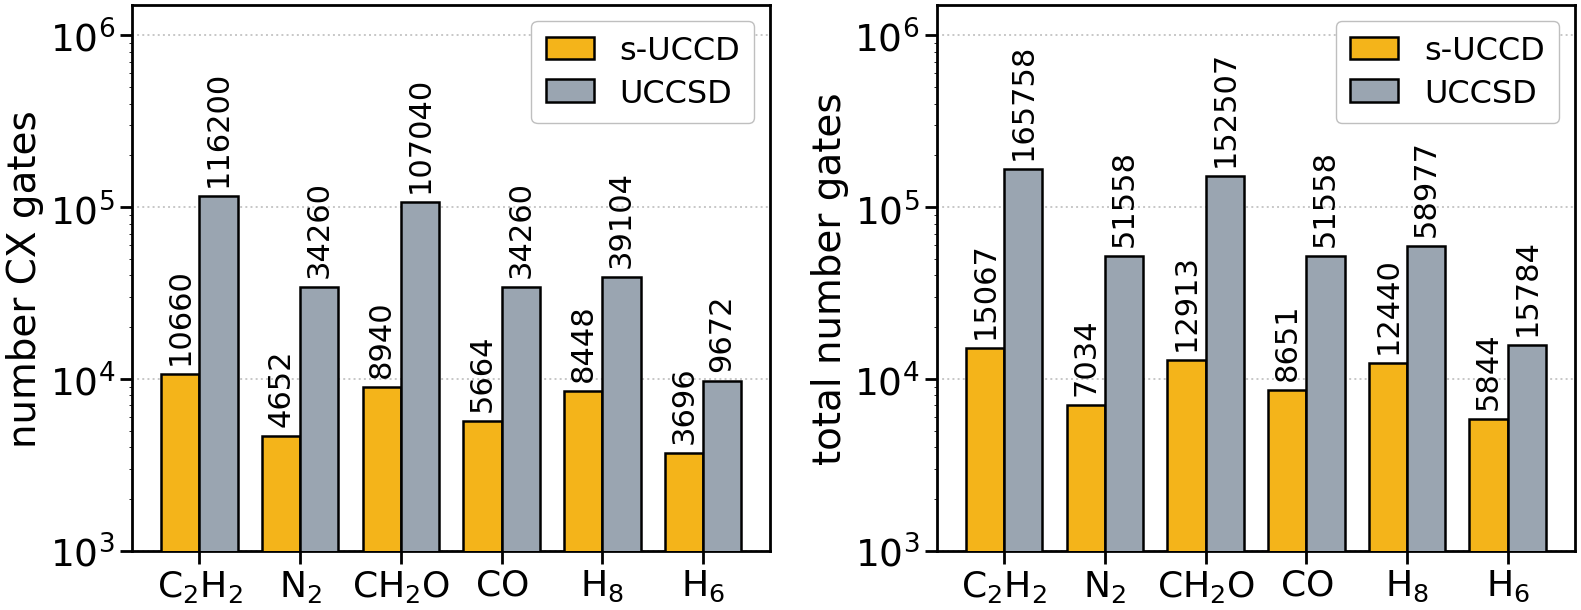

In [3]:
# ===================================================================
# FIGURE 3 — circuit cost.  Self-contained: run this cell alone.
# ===================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

# ---- SETTINGS -----------------------------------------------------
fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 27, 26, 28, 23, 22
fig_w, fig_h, dpi = 16.5, 6.8, 600
bar_w          = 0.38          # width of one bar
y_bottom, y_top = 1e3, 1.5e6   # raise y_top if numerals hit the frame
colour_sUCCD   = "#f4b41a"
colour_UCCSD   = "#9aa5b1"
order  = ["C2H2", "N2", "CH2O", "CO", "H8", "H6"]
labels = [r"$\mathrm{C_2H_2}$", r"$\mathrm{N_2}$", r"$\mathrm{CH_2O}$",
          r"$\mathrm{CO}$", r"$\mathrm{H_8}$", r"$\mathrm{H_6}$"]

# ---- STYLE --------------------------------------------------------
plt.rcParams.update({
    "font.size": fs_tick,
    "xtick.labelsize": fs_tick, "ytick.labelsize": fs_tick,
    "axes.linewidth": 2.0,
    "xtick.major.size": 9, "ytick.major.size": 9,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0,
    "legend.framealpha": 1.0, "legend.edgecolor": "0.75",
    "legend.borderpad": 0.45, "legend.handlelength": 1.5,
    "legend.columnspacing": 1.1, "legend.labelspacing": 0.35,
    "grid.linestyle": ":", "grid.linewidth": 1.4, "grid.color": "0.78",
    "hatch.linewidth": 2.2,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.06,
})

# ---- DATA ---------------------------------------------------------
df = pd.read_csv(os.path.join(paths.VALUES, "fig3_gates.csv"))
s  = df[df.ansatz == "s-UCCD"].set_index("molecule")
u  = df[df.ansatz == "UCCSD"].set_index("molecule")

cx_sUCCD    = [s.loc[m, "cx_gates"]    for m in order]
cx_UCCSD    = [u.loc[m, "cx_gates"]    for m in order]
total_sUCCD = [s.loc[m, "total_gates"] for m in order]
total_UCCSD = [u.loc[m, "total_gates"] for m in order]

x = np.arange(len(order))

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(fig_w, fig_h))

# ---- PLOT: LEFT PANEL, CX gates -----------------------------------
ax_left.set_yscale("log")
ax_left.set_ylim(y_bottom, y_top)

ax_left.bar(x - bar_w / 2, cx_sUCCD, bar_w, color=colour_sUCCD,
            edgecolor="black", linewidth=1.8, label="s-UCCD", zorder=3)
ax_left.bar(x + bar_w / 2, cx_UCCSD, bar_w, color=colour_UCCSD,
            edgecolor="black", linewidth=1.8, label="UCCSD", zorder=3)

for xi, v in zip(x - bar_w / 2, cx_sUCCD):          # numbers above the bars
    ax_left.text(xi, v * 1.144, f"{v:d}", rotation=90, ha="center",
                 va="bottom", fontsize=fs_annot, clip_on=False)
for xi, v in zip(x + bar_w / 2, cx_UCCSD):
    ax_left.text(xi, v * 1.144, f"{v:d}", rotation=90, ha="center",
                 va="bottom", fontsize=fs_annot, clip_on=False)

ax_left.set_ylabel("number CX gates", fontsize=fs_label)
ax_left.set_xticks(x)
ax_left.set_xticklabels(labels, fontsize=fs_mol)
ax_left.yaxis.set_major_locator(LogLocator(base=10, numticks=8))
ax_left.yaxis.set_minor_formatter(NullFormatter())
ax_left.grid(True, axis="y", zorder=0)
ax_left.set_axisbelow(True)
ax_left.legend(loc="upper right", fontsize=fs_legend)

# ---- PLOT: RIGHT PANEL, total gates -------------------------------
ax_right.set_yscale("log")
ax_right.set_ylim(y_bottom, y_top)

ax_right.bar(x - bar_w / 2, total_sUCCD, bar_w, color=colour_sUCCD,
             edgecolor="black", linewidth=1.8, label="s-UCCD", zorder=3)
ax_right.bar(x + bar_w / 2, total_UCCSD, bar_w, color=colour_UCCSD,
             edgecolor="black", linewidth=1.8, label="UCCSD", zorder=3)

for xi, v in zip(x - bar_w / 2, total_sUCCD):
    ax_right.text(xi, v * 1.144, f"{v:d}", rotation=90, ha="center",
                  va="bottom", fontsize=fs_annot, clip_on=False)
for xi, v in zip(x + bar_w / 2, total_UCCSD):
    ax_right.text(xi, v * 1.144, f"{v:d}", rotation=90, ha="center",
                  va="bottom", fontsize=fs_annot, clip_on=False)

ax_right.set_ylabel("total number gates", fontsize=fs_label)
ax_right.set_xticks(x)
ax_right.set_xticklabels(labels, fontsize=fs_mol)
ax_right.yaxis.set_major_locator(LogLocator(base=10, numticks=8))
ax_right.yaxis.set_minor_formatter(NullFormatter())
ax_right.grid(True, axis="y", zorder=0)
ax_right.set_axisbelow(True)
ax_right.legend(loc="upper right", fontsize=fs_legend)

# ---- SAVE ---------------------------------------------------------
fig.tight_layout()
#os.makedirs("figures_from_notebook", exist_ok=True)
os.makedirs(os.path.join(paths.FIGURES, "notebook1"), exist_ok=True)
fig.savefig(os.path.join(paths.FIGURES, "notebook1", "00_fig3_circuit_cost.png"), dpi=dpi)
#fig.savefig("figures_from_notebook/fig3_circuit_cost.pdf")
plt.show()

## Figure 4 — E(s-CCD) − E(s-UCCD) at matched operator sets

The only line figure. Three panels on a **common vertical scale** — that is the
point of the figure, so `y_bottom`/`y_top` are fixed rather than fitted per
panel. Each panel is written out separately.

The legend is at the **upper right of panel (a)**, where the curves stay below
+0.32. Titles are not used, so `(a) c_m` and friends are `ax.text` annotations
placed inside the axes in axes-fraction coordinates. One centred abscissa label
is used because at 32 pt a per-panel label is wider than a panel.

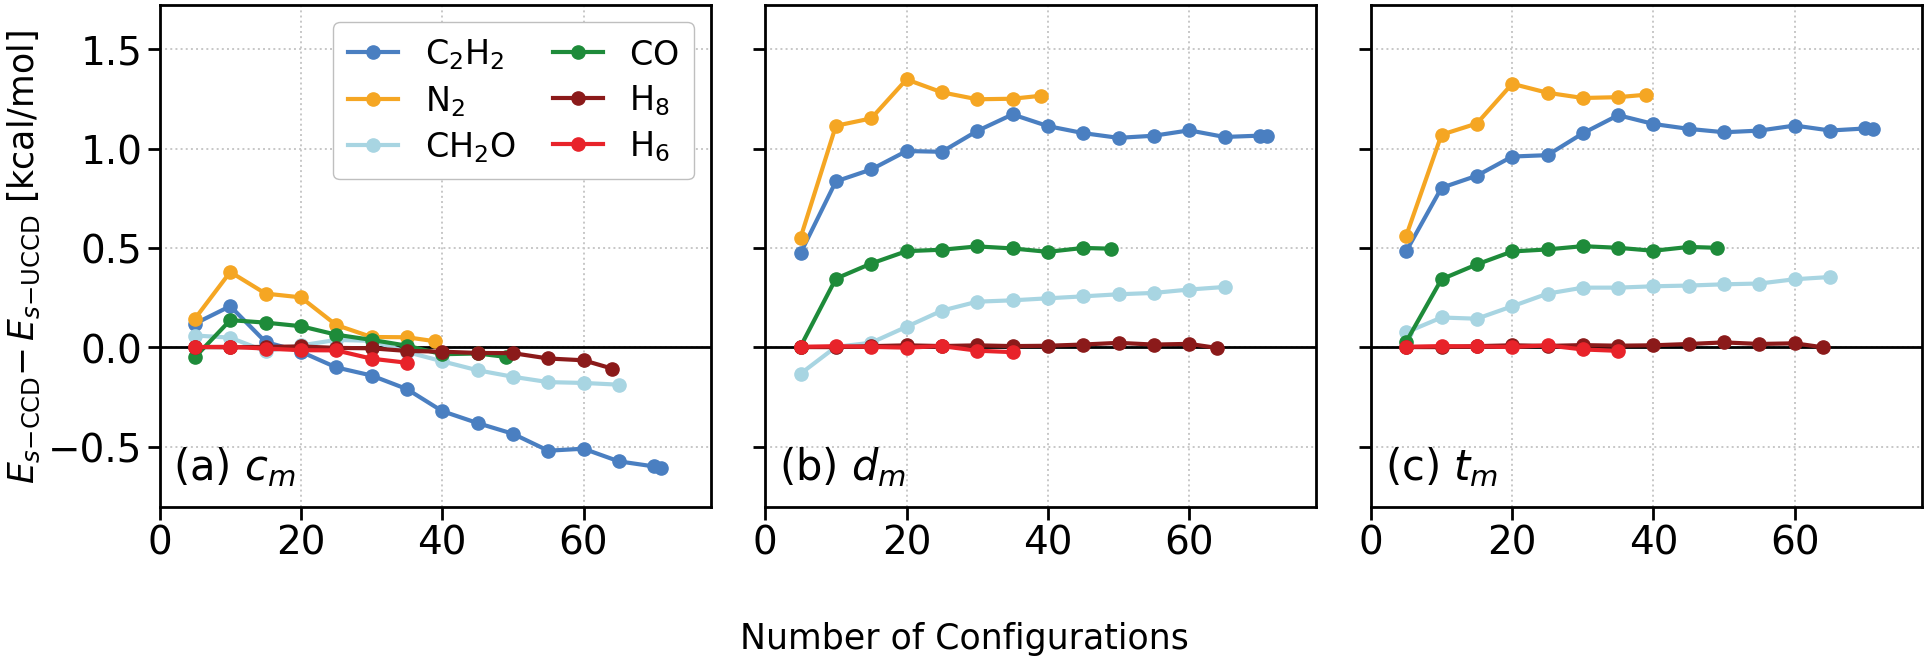

In [4]:
# ===================================================================
# FIGURE 4 — E(s-CCD) - E(s-UCCD).  Self-contained: run this cell alone.
# ===================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- SETTINGS -----------------------------------------------------
fs_tick, fs_mol, fs_label, fs_legend, fs_tag = 30, 32, 32, 27, 30
fig_w, fig_h, dpi = 20, 7, 600

fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 28, 27, 25, 24, 23


y_bottom, y_top   = -0.80, 1.72      # shared by all three panels
x_left, x_right   = 0, 78
marker_size, line_width = 9.5, 3.0
order  = ["C2H2", "N2", "CH2O", "CO", "H8", "H6"]
labels = [r"$\mathrm{C_2H_2}$", r"$\mathrm{N_2}$", r"$\mathrm{CH_2O}$",
          r"$\mathrm{CO}$", r"$\mathrm{H_8}$", r"$\mathrm{H_6}$"]
colours = ["#4a7fc1", "#f5a623", "#a8d5e2", "#1e8b3a", "#8b1a1a", "#e8232a"]

# ---- STYLE --------------------------------------------------------
plt.rcParams.update({
    "font.size": fs_tick,
    "xtick.labelsize": fs_tick, "ytick.labelsize": fs_tick,
    "axes.linewidth": 2.0,
    "xtick.major.size": 9, "ytick.major.size": 9,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0,
    "legend.framealpha": 1.0, "legend.edgecolor": "0.75",
    "legend.borderpad": 0.45, "legend.handlelength": 1.5,
    "legend.columnspacing": 1.1, "legend.labelspacing": 0.35,
    "grid.linestyle": ":", "grid.linewidth": 1.4, "grid.color": "0.78",
    "hatch.linewidth": 2.2,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.06,
})

# ---- DATA ---------------------------------------------------------
df = pd.read_csv(os.path.join(paths.VALUES, "fig4_sweep.csv"))

fig, (ax_a, ax_b, ax_c) = plt.subplots(1, 3, figsize=(fig_w, fig_h),
                                       sharey=True)

# ---- PLOT: PANEL (a), raw coefficients c_m ------------------------
ax_a.axhline(0.0, color="black", linewidth=2.0, zorder=2)
for m, lab, col in zip(order, labels, colours):
    d = df[df.molecule == m].sort_values("N")
    ax_a.plot(d["N"], d["dE_cm_kcalmol"], marker="o", markersize=marker_size,
              linewidth=line_width, color=col, label=lab, zorder=3)
ax_a.set_xlim(x_left, x_right)
ax_a.set_ylim(y_bottom, y_top)
ax_a.grid(True, zorder=0)
ax_a.set_axisbelow(True)
ax_a.text(0.025, 0.035, r"(a) $c_m$", transform=ax_a.transAxes,
          fontsize=fs_tag, ha="left", va="bottom")
ax_a.set_ylabel(r"$E_{s\mathrm{-CCD}}$"  r"$-\,E_{s\mathrm{-UCCD}}$ [kcal/mol]" ,
                fontsize=fs_label)
ax_a.legend(loc="upper right", ncol=2, fontsize=fs_legend)

# ---- PLOT: PANEL (b), rescaled coefficients d_m -------------------
ax_b.axhline(0.0, color="black", linewidth=2.0, zorder=2)
for m, lab, col in zip(order, labels, colours):
    d = df[df.molecule == m].sort_values("N")
    ax_b.plot(d["N"], d["dE_dm_kcalmol"], marker="o", markersize=marker_size,
              linewidth=line_width, color=col, label=lab, zorder=3)
ax_b.set_xlim(x_left, x_right)
ax_b.set_ylim(y_bottom, y_top)
ax_b.grid(True, zorder=0)
ax_b.set_axisbelow(True)
ax_b.text(0.025, 0.035, r"(b) $d_m$", transform=ax_b.transAxes,
          fontsize=fs_tag, ha="left", va="bottom")

# ---- PLOT: PANEL (c), s-CCD amplitudes t_m ------------------------
ax_c.axhline(0.0, color="black", linewidth=2.0, zorder=2)
for m, lab, col in zip(order, labels, colours):
    d = df[df.molecule == m].sort_values("N")
    ax_c.plot(d["N"], d["dE_tm_kcalmol"], marker="o", markersize=marker_size,
              linewidth=line_width, color=col, label=lab, zorder=3)
ax_c.set_xlim(x_left, x_right)
ax_c.set_ylim(y_bottom, y_top)
ax_c.grid(True, zorder=0)
ax_c.set_axisbelow(True)
ax_c.text(0.025, 0.035, r"(c) $t_m$", transform=ax_c.transAxes,
          fontsize=fs_tag, ha="left", va="bottom")

# ---- SAVE ---------------------------------------------------------
# rect leaves a strip at the bottom for the single centred x label
fig.tight_layout(rect=(0, 0.085, 1, 1))
fig.supxlabel("Number of Configurations", fontsize=fs_label, y=0.012)
"""os.makedirs("figures_from_notebook", exist_ok=True)

fig.savefig("figures_from_notebook/fig4_dE_matched_sets.pdf")"""
os.makedirs(os.path.join(paths.FIGURES, "notebook1"), exist_ok=True)
fig.savefig(os.path.join(paths.FIGURES, "notebook1", "00_fig4_dE_matched_sets.png"), dpi=dpi)
plt.show()

## Figure 5 — residual correlation energy

Three bars per system, at `x - bar_w`, `x`, `x + bar_w`. Lower is better; zero
is the variational optimum of the same ansatz.

For CH₂O and C₂H₂ the reference *p*ₘ was estimated through the capture factor
rather than converged, and those bars are hatched. Because the hatch differs
from bar to bar, each bar is drawn by its own `ax.bar` call inside a short
loop, and one empty `ax.bar([], [])` per series supplies the legend entry —
a bar with no data, drawn only so the legend has a clean unhatched swatch.

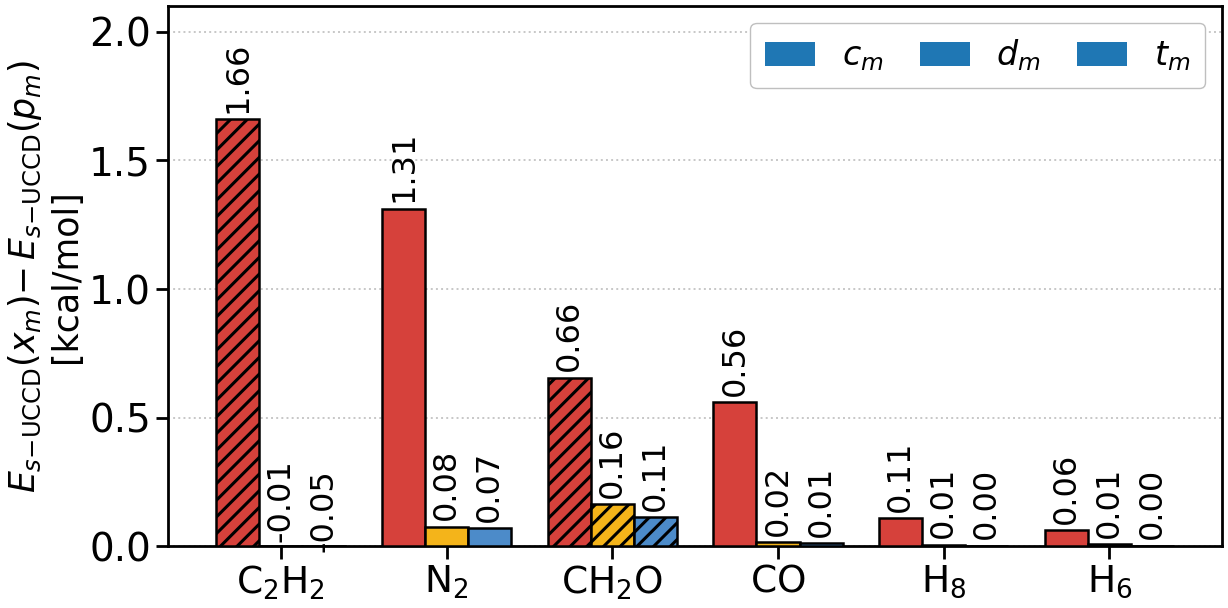

In [5]:
# ===================================================================
# FIGURE 5 — residual correlation energy.  Run this cell alone.
# ===================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- SETTINGS -----------------------------------------------------
fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 30, 32, 32, 27, 26

fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 28, 27, 25, 24, 23

fig_w, fig_h, dpi = 13.0, 6.8, 600
bar_w           = 0.26
y_bottom, y_top = 0, 2.10        # raise y_top if numerals hit the frame
annot_pad       = 0.012          # gap above the bar, as a fraction of the axes
colour_c, colour_d, colour_t = "#d6413b", "#f4b41a", "#4c8bc9"

order  = ["C2H2", "N2", "CH2O", "CO", "H8", "H6"]
labels = [r"$\mathrm{C_2H_2}$", r"$\mathrm{N_2}$", r"$\mathrm{CH_2O}$",
          r"$\mathrm{CO}$", r"$\mathrm{H_8}$", r"$\mathrm{H_6}$"]

# ---- STYLE --------------------------------------------------------
plt.rcParams.update({
    "font.size": fs_tick,
    "xtick.labelsize": fs_tick, "ytick.labelsize": fs_tick,
    "axes.linewidth": 2.0,
    "xtick.major.size": 9, "ytick.major.size": 9,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0,
    "legend.framealpha": 1.0, "legend.edgecolor": "0.75",
    "legend.borderpad": 0.45, "legend.handlelength": 1.5,
    "legend.columnspacing": 1.1, "legend.labelspacing": 0.35,
    "grid.linestyle": ":", "grid.linewidth": 1.4, "grid.color": "0.78",
    "hatch.linewidth": 2.2,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.06,
})

# ---- DATA ---------------------------------------------------------
df = pd.read_csv(os.path.join(paths.VALUES, "fig5_residual.csv"))
c = df[df.source == "c_m"].set_index("molecule")
d = df[df.source == "d_m"].set_index("molecule")
t = df[df.source == "t_m"].set_index("molecule")

res_c = [c.loc[m, "residual_kcalmol"] for m in order]
res_d = [d.loc[m, "residual_kcalmol"] for m in order]
res_t = [t.loc[m, "residual_kcalmol"] for m in order]
# "//" where p_m was estimated rather than converged, "" otherwise
hatch = ["//" if c.loc[m, "pm_estimated"] else "" for m in order]

x   = np.arange(len(order))
pad = annot_pad * (y_top - y_bottom)

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_ylim(y_bottom, y_top)

# ---- PLOT: three series, one bar at a time so the hatch can vary ---
for xi, v, h in zip(x - bar_w, res_c, hatch):
    ax.bar(xi, v, bar_w, color=colour_c, edgecolor="black", linewidth=1.8,
           hatch=h, zorder=3)
    
for xi, v, h in zip(x, res_d, hatch):
    ax.bar(xi, v, bar_w, color=colour_d, edgecolor="black", linewidth=1.8,
           hatch=h, zorder=3)
    
for xi, v, h in zip(x + bar_w, res_t, hatch):
    ax.bar(xi, v, bar_w, color=colour_t, edgecolor="black", linewidth=1.8,
           hatch=h, zorder=3)

# empty bars: they draw nothing, they exist only to label the legend
ax.bar([], [], color=colour_c, edgecolor="black", linewidth=1.8, label=r"$c_m$")
ax.bar([], [], color=colour_d, edgecolor="black", linewidth=1.8, label=r"$d_m$")
ax.bar([], [], color=colour_t, edgecolor="black", linewidth=1.8, label=r"$t_m$")

# ---- PLOT: numbers above the bars ---------------------------------
for xi, v in zip(x - bar_w, res_c):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x, res_d):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x + bar_w, res_t):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)

ax.set_ylabel(r"$E_{s\mathrm{-UCCD}}(x_m)$" 
              r"$-\,E_{s\mathrm{-UCCD}}(p_m)$" "\n[kcal/mol]",
              fontsize=fs_label)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=fs_mol)
ax.grid(True, axis="y", zorder=0)
ax.set_axisbelow(True)
ax.legend(loc="upper right", ncol=3, fontsize=fs_legend)

# ---- SAVE ---------------------------------------------------------
fig.tight_layout()
#os.makedirs("figures_from_notebook", exist_ok=True)
#fig.savefig("figures_from_notebook/fig5_residual_correlation.png", dpi=dpi)
#fig.savefig("figures_from_notebook/fig5_residual_correlation.pdf")
plt.show()

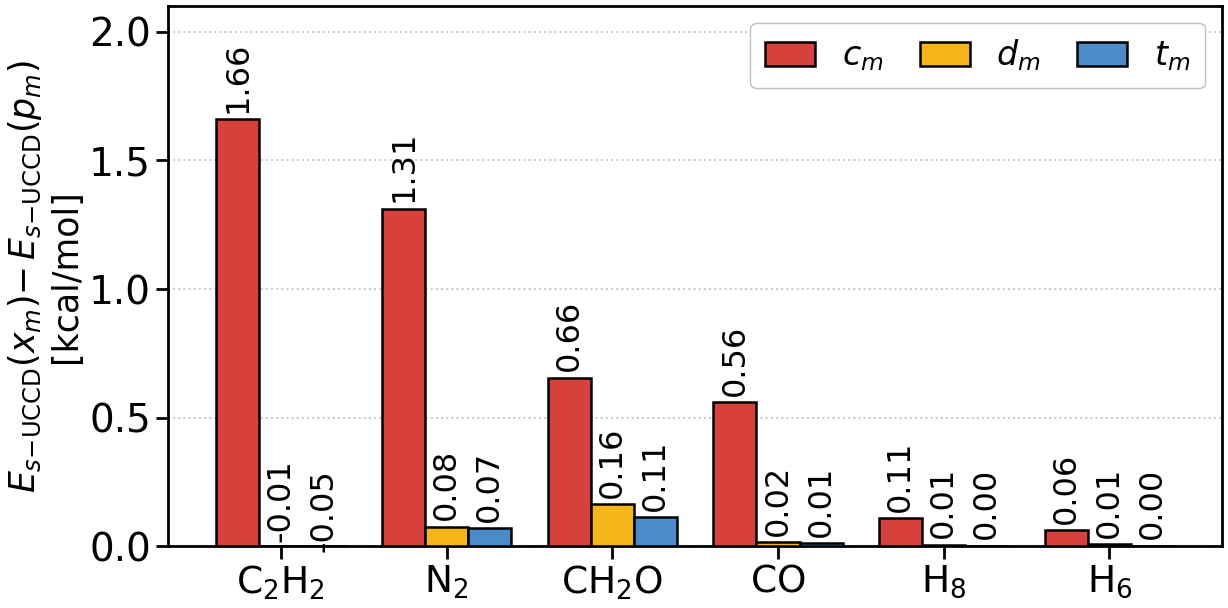

In [6]:
# ===================================================================
# FIGURE 5 — residual correlation energy.  Run this cell alone.
# ===================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- SETTINGS -----------------------------------------------------
fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 30, 32, 32, 27, 26

fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 28, 27, 25, 24, 23

fig_w, fig_h, dpi = 13.0, 6.8, 600
bar_w           = 0.26
y_bottom, y_top = 0, 2.10        # raise y_top if numerals hit the frame
annot_pad       = 0.012          # gap above the bar, as a fraction of the axes
colour_c, colour_d, colour_t = "#d6413b", "#f4b41a", "#4c8bc9"

order  = ["C2H2", "N2", "CH2O", "CO", "H8", "H6"]
labels = [r"$\mathrm{C_2H_2}$", r"$\mathrm{N_2}$", r"$\mathrm{CH_2O}$",
          r"$\mathrm{CO}$", r"$\mathrm{H_8}$", r"$\mathrm{H_6}$"]

# ---- STYLE --------------------------------------------------------
plt.rcParams.update({
    "font.size": fs_tick,
    "xtick.labelsize": fs_tick, "ytick.labelsize": fs_tick,
    "axes.linewidth": 2.0,
    "xtick.major.size": 9, "ytick.major.size": 9,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0,
    "legend.framealpha": 1.0, "legend.edgecolor": "0.75",
    "legend.borderpad": 0.45, "legend.handlelength": 1.5,
    "legend.columnspacing": 1.1, "legend.labelspacing": 0.35,
    "grid.linestyle": ":", "grid.linewidth": 1.4, "grid.color": "0.78",
    "savefig.bbox": "tight", "savefig.pad_inches": 0.06,
})

# ---- DATA ---------------------------------------------------------
df = pd.read_csv(os.path.join(paths.VALUES, "fig5_residual.csv"))
c = df[df.source == "c_m"].set_index("molecule")
d = df[df.source == "d_m"].set_index("molecule")
t = df[df.source == "t_m"].set_index("molecule")

res_c = [c.loc[m, "residual_kcalmol"] for m in order]
res_d = [d.loc[m, "residual_kcalmol"] for m in order]
res_t = [t.loc[m, "residual_kcalmol"] for m in order]

x   = np.arange(len(order))
pad = annot_pad * (y_top - y_bottom)

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_ylim(y_bottom, y_top)

# ---- PLOT: three series -------------------------------------------
ax.bar(x - bar_w, res_c, bar_w, color=colour_c, edgecolor="black",
       linewidth=1.8, zorder=3, label=r"$c_m$")
ax.bar(x, res_d, bar_w, color=colour_d, edgecolor="black",
       linewidth=1.8, zorder=3, label=r"$d_m$")
ax.bar(x + bar_w, res_t, bar_w, color=colour_t, edgecolor="black",
       linewidth=1.8, zorder=3, label=r"$t_m$")

# ---- PLOT: numbers above the bars ---------------------------------
for xi, v in zip(x - bar_w, res_c):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x, res_d):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x + bar_w, res_t):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)

ax.set_ylabel(r"$E_{s\mathrm{-UCCD}}(x_m)$" 
              r"$-\,E_{s\mathrm{-UCCD}}(p_m)$" "\n[kcal/mol]",
              fontsize=fs_label)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=fs_mol)
ax.grid(True, axis="y", zorder=0)
ax.set_axisbelow(True)
ax.legend(loc="upper right", ncol=3, fontsize=fs_legend)

# ---- SAVE ---------------------------------------------------------
fig.tight_layout()
#os.makedirs("figures_from_notebook", exist_ok=True)
os.makedirs(os.path.join(paths.FIGURES, "notebook1"), exist_ok=True)
fig.savefig(os.path.join(paths.FIGURES, "notebook1", "00_fig5_residual_correlation.png"), dpi=dpi)
#fig.savefig("figures_from_notebook/fig5_residual_correlation.pdf")
plt.show()

## Figure 6 — quadruple correlation energy

Blue and amber: the surplus of the s-UCCD circuit over the s-CID
diagonalisation performed with the same operators and parameters. Green: the
energy recovered when the quadruple determinants are added explicitly to the
linear CI. The three bars nearly coincide, and that coincidence is the result.

No hatching here, so each series is a single `ax.bar` call with its own label
and the legend follows automatically. The legend entries are long expressions,
so this figure uses a smaller `fs_legend` than the others.

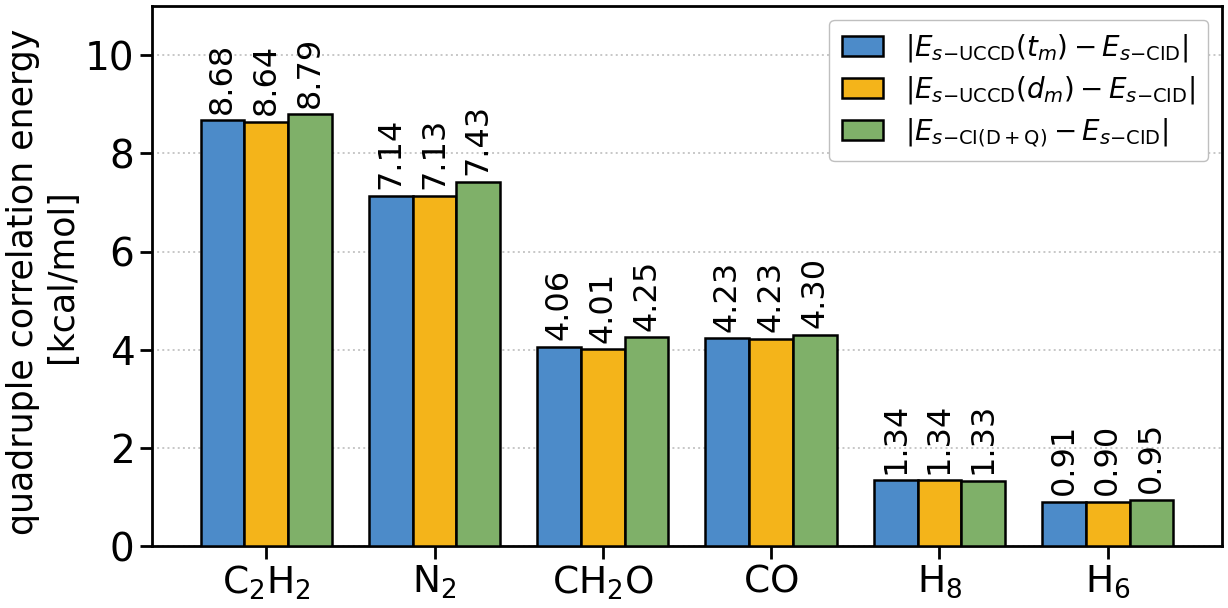

In [7]:
# ===================================================================
# FIGURE 6 — quadruple correlation energy.  Run this cell alone.
# ===================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- SETTINGS -----------------------------------------------------
fs_tick, fs_mol, fs_label, fs_annot = 30, 32, 32, 26
fs_legend       = 23             # smaller: these entries are long expressions
fig_w, fig_h, dpi = 13.0, 6.8, 600
bar_w           = 0.26
y_bottom, y_top = 0, 11.0        # raise y_top if numerals hit the frame
annot_pad       = 0.012
colour_t, colour_d, colour_Q = "#4c8bc9", "#f4b41a", "#7fb069"
order  = ["C2H2", "N2", "CH2O", "CO", "H8", "H6"]
labels = [r"$\mathrm{C_2H_2}$", r"$\mathrm{N_2}$", r"$\mathrm{CH_2O}$",
          r"$\mathrm{CO}$", r"$\mathrm{H_8}$", r"$\mathrm{H_6}$"]

fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 28, 27, 25, 20, 23

# ---- STYLE --------------------------------------------------------
plt.rcParams.update({
    "font.size": fs_tick,
    "xtick.labelsize": fs_tick, "ytick.labelsize": fs_tick,
    "axes.linewidth": 2.0,
    "xtick.major.size": 9, "ytick.major.size": 9,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0,
    "legend.framealpha": 1.0, "legend.edgecolor": "0.75",
    "legend.borderpad": 0.45, "legend.handlelength": 1.5,
    "legend.columnspacing": 1.1, "legend.labelspacing": 0.35,
    "grid.linestyle": ":", "grid.linewidth": 1.4, "grid.color": "0.78",
    "hatch.linewidth": 2.2,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.06,
})

# ---- DATA ---------------------------------------------------------
df = pd.read_csv(os.path.join(paths.VALUES, "fig6_quadruples.csv"))
name_t = "|E_sUCCD(t_m) - E_sCID|"
name_d = "|E_sUCCD(d_m) - E_sCID|"
name_Q = "|E_sCI(D+Q) - E_sCID|"

t = df[df.quantity == name_t].set_index("molecule")
d = df[df.quantity == name_d].set_index("molecule")
Q = df[df.quantity == name_Q].set_index("molecule")

val_t = [t.loc[m, "energy_kcalmol"] for m in order]
val_d = [d.loc[m, "energy_kcalmol"] for m in order]
val_Q = [Q.loc[m, "energy_kcalmol"] for m in order]

x   = np.arange(len(order))
pad = annot_pad * (y_top - y_bottom)

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_ylim(y_bottom, y_top)

# ---- PLOT: three series -------------------------------------------
ax.bar(x - bar_w, val_t, bar_w, color=colour_t, edgecolor="black",
       linewidth=1.8, zorder=3,
       label=r"$|E_{s\mathrm{-UCCD}}(t_m)-E_{s\mathrm{-CID}}|$")
ax.bar(x,         val_d, bar_w, color=colour_d, edgecolor="black",
       linewidth=1.8, zorder=3,
       label=r"$|E_{s\mathrm{-UCCD}}(d_m)-E_{s\mathrm{-CID}}|$")
ax.bar(x + bar_w, val_Q, bar_w, color=colour_Q, edgecolor="black",
       linewidth=1.8, zorder=3,
       label=r"$|E_{s\mathrm{-CI(D+Q)}}-E_{s\mathrm{-CID}}|$")

# ---- PLOT: numbers above the bars ---------------------------------
for xi, v in zip(x - bar_w, val_t):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x, val_d):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x + bar_w, val_Q):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)

ax.set_ylabel("quadruple correlation energy \n[kcal/mol]", fontsize=fs_label)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=fs_mol)
ax.grid(True, axis="y", zorder=0)
ax.set_axisbelow(True)
ax.legend(loc="upper right", fontsize=fs_legend)

# ---- SAVE ---------------------------------------------------------
fig.tight_layout()
#os.makedirs("figures_from_notebook", exist_ok=True)
os.makedirs(os.path.join(paths.FIGURES, "notebook1"), exist_ok=True)
fig.savefig(os.path.join(paths.FIGURES, "notebook1", "00_fig6_quadruple_correlation_energy.png"),
            dpi=dpi)
#fig.savefig("figures_from_notebook/fig6_quadruple_correlation_energy.pdf")
plt.show()

## Figure A1 — Enhanced CISD

Deviation from frozen-core FCI of CISD, of the Enhanced CISD of Eq. 10 in the
*d*ₘ parameterisation, and of CCSD. All three are non-negative, since FCI is
variationally lowest.

The dashed line is chemical accuracy, 1 kcal/mol, drawn with `zorder=4` so it
stays visible where it crosses the bars.

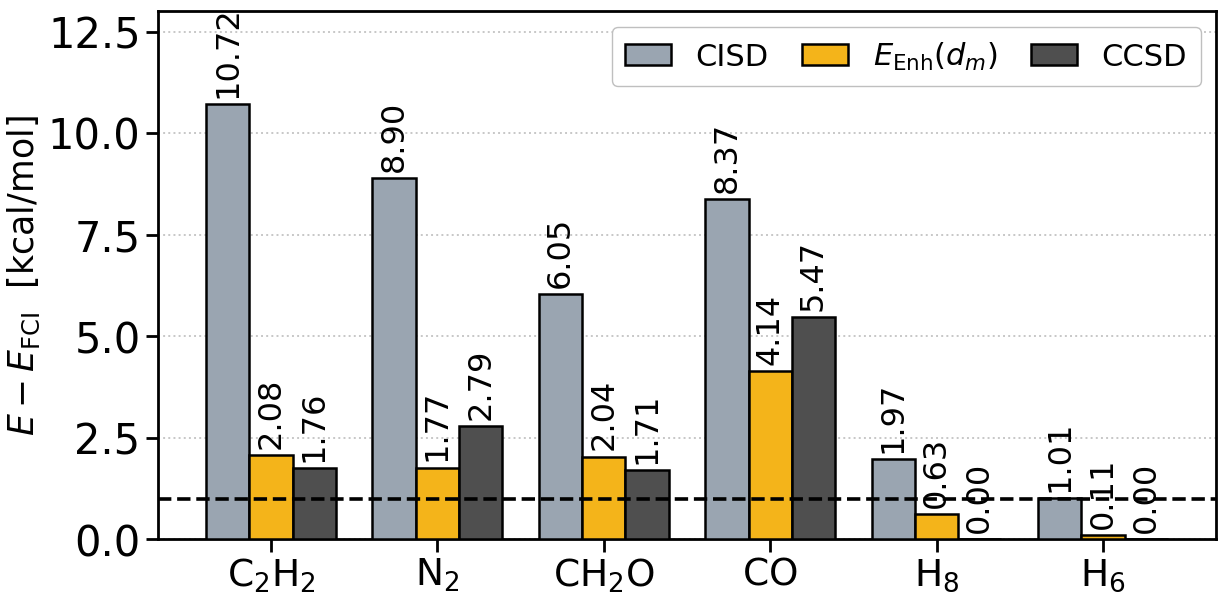

In [8]:
# ===================================================================
# FIGURE A1 — Enhanced CISD.  Run this cell alone.
# ===================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- SETTINGS -----------------------------------------------------
fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 30, 32, 32, 27, 26
fig_w, fig_h, dpi = 13.0, 6.8, 600
bar_w           = 0.26
y_bottom, y_top = 0, 13.0        # raise y_top if numerals hit the frame
annot_pad       = 0.012
chemical_accuracy = 1.0
colour_CISD, colour_Enh, colour_CCSD = "#9aa5b1", "#f4b41a", "#4f4f4f"
order  = ["C2H2", "N2", "CH2O", "CO", "H8", "H6"]
labels = [r"$\mathrm{C_2H_2}$", r"$\mathrm{N_2}$", r"$\mathrm{CH_2O}$",
          r"$\mathrm{CO}$", r"$\mathrm{H_8}$", r"$\mathrm{H_6}$"]

# ---- STYLE --------------------------------------------------------
plt.rcParams.update({
    "font.size": fs_tick,
    "xtick.labelsize": fs_tick, "ytick.labelsize": fs_tick,
    "axes.linewidth": 2.0,
    "xtick.major.size": 9, "ytick.major.size": 9,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0,
    "legend.framealpha": 1.0, "legend.edgecolor": "0.75",
    "legend.borderpad": 0.45, "legend.handlelength": 1.5,
    "legend.columnspacing": 1.1, "legend.labelspacing": 0.35,
    "grid.linestyle": ":", "grid.linewidth": 1.4, "grid.color": "0.78",
    "hatch.linewidth": 2.2,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.06,
})

fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 28, 27, 25, 22, 23

# ---- DATA ---------------------------------------------------------
df   = pd.read_csv(os.path.join(paths.VALUES, "figA1_enhanced_cisd.csv"))
cisd = df[df.method == "CISD"].set_index("molecule")
enh  = df[df.method == "Enh(d_m)"].set_index("molecule")
ccsd = df[df.method == "CCSD"].set_index("molecule")

val_CISD = [cisd.loc[m, "dev_from_FCI_kcalmol"] for m in order]
val_Enh  = [enh.loc[m,  "dev_from_FCI_kcalmol"] for m in order]
val_CCSD = [ccsd.loc[m, "dev_from_FCI_kcalmol"] for m in order]

x   = np.arange(len(order))
pad = annot_pad * (y_top - y_bottom)

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_ylim(y_bottom, y_top)

# ---- PLOT: three series -------------------------------------------
ax.bar(x - bar_w, val_CISD, bar_w, color=colour_CISD, edgecolor="black",
       linewidth=1.8, label="CISD", zorder=3)
ax.bar(x,         val_Enh,  bar_w, color=colour_Enh,  edgecolor="black",
       linewidth=1.8, label=r"$E_{\mathrm{Enh}}(d_m)$", zorder=3)
ax.bar(x + bar_w, val_CCSD, bar_w, color=colour_CCSD, edgecolor="black",
       linewidth=1.8, label="CCSD", zorder=3)

# ---- PLOT: numbers above the bars ---------------------------------
for xi, v in zip(x - bar_w, val_CISD):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x, val_Enh):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x + bar_w, val_CCSD):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)

# chemical accuracy, drawn on top of the bars
ax.axhline(chemical_accuracy, color="black", linestyle="--", linewidth=2.6,
           zorder=4)

ax.set_ylabel(r"$E-E_{\mathrm{FCI}}$  [kcal/mol]", fontsize=fs_label)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=fs_mol)
ax.grid(True, axis="y", zorder=0)
ax.set_axisbelow(True)
ax.legend(loc="upper right", ncol=3, fontsize=fs_legend)

# ---- SAVE ---------------------------------------------------------
fig.tight_layout()
#os.makedirs("figures_from_notebook", exist_ok=True)
os.makedirs(os.path.join(paths.FIGURES, "notebook1"), exist_ok=True)
fig.savefig(os.path.join(paths.FIGURES, "notebook1", "00_figA1_enhanced_cisd.png"), dpi=dpi)
#fig.savefig("figures_from_notebook/figA1_enhanced_cisd.pdf")
plt.show()

## Figure A2 — SQD deviation at 10⁸ measurements

Six bars per system, at `x - 2.5·bar_w` through `x + 2.5·bar_w`. Two things are
encoded, so each gets its own channel: **colour** is the parameter source
(*c*ₘ red, *d*ₘ amber, *t*ₘ blue) and **hatch** is the subspace (plain = SQD-D,
hatched = SQD-SD). Compare a plain bar with the hatched bar of the same colour
to see whether the singles help.

No numbers are printed: at `bar_w = 0.14` a rotated numeral would be wider than
its bar. The values are in `values/figA2_sqd.csv`.

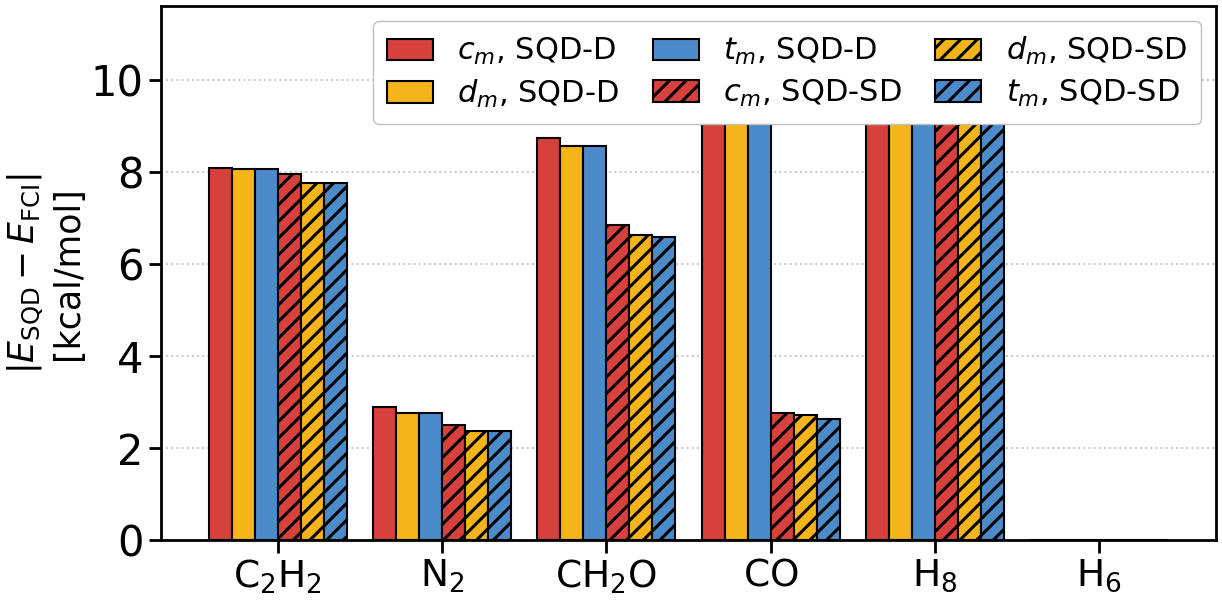

In [9]:
# ===================================================================
# FIGURE A2 — SQD deviation at 1e8 measurements.  Run this cell alone.
# ===================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- SETTINGS -----------------------------------------------------
fs_tick, fs_mol, fs_label = 30, 32, 32
fs_legend       = 24             # smaller: six entries have to fit
fig_w, fig_h, dpi = 13.0, 6.8, 600
bar_w           = 0.14
y_bottom, y_top = 0, 11.6
colour_c, colour_d, colour_t = "#d6413b", "#f4b41a", "#4c8bc9"
order  = ["C2H2", "N2", "CH2O", "CO", "H8", "H6"]
labels = [r"$\mathrm{C_2H_2}$", r"$\mathrm{N_2}$", r"$\mathrm{CH_2O}$",
          r"$\mathrm{CO}$", r"$\mathrm{H_8}$", r"$\mathrm{H_6}$"]

# ---- STYLE --------------------------------------------------------
plt.rcParams.update({
    "font.size": fs_tick,
    "xtick.labelsize": fs_tick, "ytick.labelsize": fs_tick,
    "axes.linewidth": 2.0,
    "xtick.major.size": 9, "ytick.major.size": 9,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0,
    "legend.framealpha": 1.0, "legend.edgecolor": "0.75",
    "legend.borderpad": 0.45, "legend.handlelength": 1.5,
    "legend.columnspacing": 1.1, "legend.labelspacing": 0.35,
    "grid.linestyle": ":", "grid.linewidth": 1.4, "grid.color": "0.78",
    "hatch.linewidth": 2.2,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.06,
})

fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 28, 27, 25, 22, 23
# ---- DATA ---------------------------------------------------------
df  = pd.read_csv(os.path.join(paths.VALUES, "figA2_sqd.csv"))
col = "abs_dev_from_FCI_kcalmol"

cD  = df[(df.parameters == "c") & (df.subspace == "SQD-D")].set_index("molecule")
dD  = df[(df.parameters == "d") & (df.subspace == "SQD-D")].set_index("molecule")
tD  = df[(df.parameters == "t") & (df.subspace == "SQD-D")].set_index("molecule")
cSD = df[(df.parameters == "c") & (df.subspace == "SQD-SD")].set_index("molecule")
dSD = df[(df.parameters == "d") & (df.subspace == "SQD-SD")].set_index("molecule")
tSD = df[(df.parameters == "t") & (df.subspace == "SQD-SD")].set_index("molecule")

val_cD  = [cD.loc[m, col]  for m in order]
val_dD  = [dD.loc[m, col]  for m in order]
val_tD  = [tD.loc[m, col]  for m in order]
val_cSD = [cSD.loc[m, col] for m in order]
val_dSD = [dSD.loc[m, col] for m in order]
val_tSD = [tSD.loc[m, col] for m in order]

x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_ylim(y_bottom, y_top)

# ---- PLOT: six series, plain = SQD-D, hatched = SQD-SD ------------
ax.bar(x - 2.5 * bar_w, val_cD,  bar_w, color=colour_c, edgecolor="black",
       linewidth=1.5, zorder=3, label=r"$c_m$, SQD-D")
ax.bar(x - 1.5 * bar_w, val_dD,  bar_w, color=colour_d, edgecolor="black",
       linewidth=1.5, zorder=3, label=r"$d_m$, SQD-D")
ax.bar(x - 0.5 * bar_w, val_tD,  bar_w, color=colour_t, edgecolor="black",
       linewidth=1.5, zorder=3, label=r"$t_m$, SQD-D")
ax.bar(x + 0.5 * bar_w, val_cSD, bar_w, color=colour_c, edgecolor="black",
       linewidth=1.5, zorder=3, hatch="//", label=r"$c_m$, SQD-SD")
ax.bar(x + 1.5 * bar_w, val_dSD, bar_w, color=colour_d, edgecolor="black",
       linewidth=1.5, zorder=3, hatch="//", label=r"$d_m$, SQD-SD")
ax.bar(x + 2.5 * bar_w, val_tSD, bar_w, color=colour_t, edgecolor="black",
       linewidth=1.5, zorder=3, hatch="//", label=r"$t_m$, SQD-SD")

ax.set_ylabel(r"$|E_{\mathrm{SQD}}-E_{\mathrm{FCI}}|$" "\n[kcal/mol]",
              fontsize=fs_label)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=fs_mol)
ax.grid(True, axis="y", zorder=0)
ax.set_axisbelow(True)
ax.legend(loc="upper right", ncol=3, fontsize=fs_legend)

# ---- SAVE ---------------------------------------------------------
fig.tight_layout()
#os.makedirs("figures_from_notebook", exist_ok=True)
os.makedirs(os.path.join(paths.FIGURES, "notebook1"), exist_ok=True)
fig.savefig(os.path.join(paths.FIGURES, "notebook1", "00_figA2_sqd_deviation.png"), dpi=dpi)
#fig.savefig("figures_from_notebook/figA2_sqd_deviation.pdf")
plt.show()

## Figure A3 — determinants entering the diagonalisation

The size of the subspace actually diagonalised against the full determinant
space. The counts run from 83 to 63 504, so the ordinate is logarithmic and the
gap — which is the message — reads as a vertical distance. On a log axis the
numerals are offset by a factor (`× 1.144`) rather than an additive amount, and
`f"{v:d}"` prints integers rather than `63504.00`.

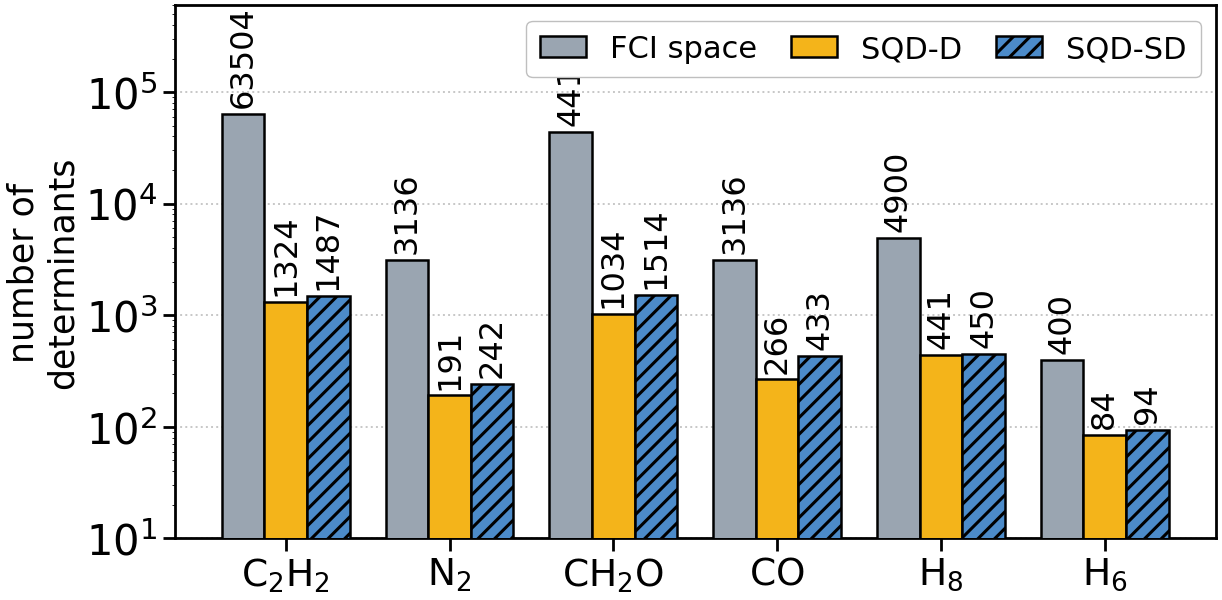

In [10]:
# ===================================================================
# FIGURE A3 — determinant counts.  Run this cell alone.
# ===================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

# ---- SETTINGS -----------------------------------------------------
fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 30, 32, 32, 27, 26
fig_w, fig_h, dpi = 13.0, 6.8, 600
bar_w           = 0.26
y_bottom, y_top = 10, 6.0e5      # raise y_top if numerals hit the frame
colour_FCI, colour_D, colour_SD = "#9aa5b1", "#f4b41a", "#4c8bc9"
order  = ["C2H2", "N2", "CH2O", "CO", "H8", "H6"]
labels = [r"$\mathrm{C_2H_2}$", r"$\mathrm{N_2}$", r"$\mathrm{CH_2O}$",
          r"$\mathrm{CO}$", r"$\mathrm{H_8}$", r"$\mathrm{H_6}$"]

# ---- STYLE --------------------------------------------------------
plt.rcParams.update({
    "font.size": fs_tick,
    "xtick.labelsize": fs_tick, "ytick.labelsize": fs_tick,
    "axes.linewidth": 2.0,
    "xtick.major.size": 9, "ytick.major.size": 9,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0,
    "legend.framealpha": 1.0, "legend.edgecolor": "0.75",
    "legend.borderpad": 0.45, "legend.handlelength": 1.5,
    "legend.columnspacing": 1.1, "legend.labelspacing": 0.35,
    "grid.linestyle": ":", "grid.linewidth": 1.4, "grid.color": "0.78",
    "hatch.linewidth": 2.2,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.06,
})
fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 28, 27, 25, 22, 23
# ---- DATA ---------------------------------------------------------
df  = pd.read_csv(os.path.join(paths.VALUES, "figA3_determinants.csv"))
fci = df[df.series == "FCI space"].set_index("molecule")
sD  = df[df.series == "SQD-D"].set_index("molecule")
sSD = df[df.series == "SQD-SD"].set_index("molecule")

val_FCI = [fci.loc[m, "count"] for m in order]
val_D   = [sD.loc[m,  "count"] for m in order]
val_SD  = [sSD.loc[m, "count"] for m in order]

x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_yscale("log")
ax.set_ylim(y_bottom, y_top)

# ---- PLOT: three series -------------------------------------------
ax.bar(x - bar_w, val_FCI, bar_w, color=colour_FCI, edgecolor="black",
       linewidth=1.8, label="FCI space", zorder=3)
ax.bar(x,         val_D,   bar_w, color=colour_D,   edgecolor="black",
       linewidth=1.8, label="SQD-D", zorder=3)
ax.bar(x + bar_w, val_SD,  bar_w, color=colour_SD,  edgecolor="black",
       linewidth=1.8, label="SQD-SD", hatch="//", zorder=3)

# ---- PLOT: numbers above the bars (log axis -> multiply, not add) --
for xi, v in zip(x - bar_w, val_FCI):
    ax.text(xi, v * 1.144, f"{v:d}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x, val_D):
    ax.text(xi, v * 1.144, f"{v:d}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x + bar_w, val_SD):
    ax.text(xi, v * 1.144, f"{v:d}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)

ax.set_ylabel("number of\ndeterminants", fontsize=fs_label)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=fs_mol)
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=8))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.grid(True, axis="y", zorder=0)
ax.set_axisbelow(True)
ax.legend(loc="upper right", ncol=3, fontsize=fs_legend)

# ---- SAVE ---------------------------------------------------------
fig.tight_layout()
#os.makedirs("figures_from_notebook", exist_ok=True)
os.makedirs(os.path.join(paths.FIGURES, "notebook1"), exist_ok=True)
fig.savefig(os.path.join(paths.FIGURES, "notebook1", "00_figA3_determinant_counts.png"), dpi=dpi)
#fig.savefig("figures_from_notebook/figA3_determinant_counts.pdf")
plt.show()

## Notes

**Changing a figure.** Edit the `SETTINGS` block of that cell and re-run it.
Nothing else in the notebook affects it — every cell sets its own style, so
re-running one cell is always enough.

**Bigger text needs more head-room.** The numerals sit above the bars, so if
you raise `fs_annot` you will usually have to raise `y_top` in the same cell.
Nothing does this for you. Two symptoms to watch for: a numeral running into
the frame, and two numerals touching each other. The first is fixed by raising
`y_top`, the second by widening `fig_w` or reducing `fs_annot`.

**Why the numerals are rotated.** Rotated 90°, a numeral takes up only its cap
height horizontally — about `0.73 × fs_annot` — instead of its full string
width, which is what lets them be 26 pt in a three-bar group. It is not a
guarantee: past roughly 34 pt the cap height exceeds the bar spacing and
neighbours touch again.

**Two values that look like magic numbers.** `1.144` is the multiplicative gap
above a bar on a logarithmic axis, the counterpart of `annot_pad` on a linear
one. `zorder=3` puts the bars above the grid, and `set_axisbelow(True)` keeps
the grid behind them.

In [11]:
# ===================================================================
# PROVENANCE CHECK — run this to confirm values/ holds the delta = 3e-4 set.
# Appended at the end so every cell index above is unchanged.
# ===================================================================
import os, pandas as pd

EXPECT = {"H6": 3696, "N2": 4652, "CO": 5664, "H8": 8448,
          "CH2O": 8940, "C2H2": 10660}          # CX gates, s-UCCD, delta = 3e-4

g = pd.read_csv(os.path.join(paths.VALUES, "fig3_gates.csv"))
s = g[g.ansatz == "s-UCCD"].set_index("molecule")["cx_gates"].to_dict()

ok = all(s.get(m) == v for m, v in EXPECT.items())
print("data/values/ is the delta = 3e-4 set:", ok)
for m in ["C2H2", "N2", "CH2O", "CO", "H8", "H6"]:
    print("  %-5s CX = %-7s expected %s" % (m, s.get(m), EXPECT[m]))
if not ok:
    print("\n!! These are not the delta = 3e-4 CSVs. Point values/ at the")
    print("   folder shipped with this notebook before running the cells above.")


data/values/ is the delta = 3e-4 set: True
  C2H2  CX = 10660   expected 10660
  N2    CX = 4652    expected 4652
  CH2O  CX = 8940    expected 8940
  CO    CX = 5664    expected 5664
  H8    CX = 8448    expected 8448
  H6    CX = 3696    expected 3696


## Part B — supporting figures and SI Figure S4

# JCTC_QC_V20 - figures for the rewritten sections

Every value is read from `values/*.csv` and `values/*.json`; nothing is typed
in.  Three figures:

1. the four closed forms against the located optimum (SI Table 3);
2. Eq. 2 as a selection rule - admitted operators against two-qubit fidelity;
3. the two independent tests of Eq. 5 (energy fraction recovered, and the
   amplitude-norm ratio).

In [12]:
import json, math, csv, glob, os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# house style of the article figures (r18): boxed axes, dotted y-grid,
# large fonts, black bar edges, mathtext for symbols.
matplotlib.rcParams.update({
    'font.size': 20, 'axes.labelsize': 20, 'axes.titlesize': 20,
    'xtick.labelsize': 20, 'ytick.labelsize': 20, 'legend.fontsize': 18,
    'font.family': 'DejaVu Sans', 'mathtext.fontset': 'dejavusans',
    'axes.linewidth': 2.0, 'xtick.major.width': 2.0, 'ytick.major.width': 2.0,
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'axes.spines.top': True, 'axes.spines.right': True,
    'axes.grid': True, 'axes.grid.axis': 'y',
    'grid.linestyle': ':', 'grid.linewidth': 1.0, 'grid.color': '0.6',
    'axes.axisbelow': True,
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
})
BAR = dict(edgecolor='black', linewidth=1.6)
C_RED, C_YEL, C_BLU = '#D6392E', '#F2B233', '#2E75B6'

ROOT = paths.ROOT
FIGDIR = os.path.join(paths.FIGURES, 'notebook1'); os.makedirs(FIGDIR, exist_ok=True)
T  = json.load(open(paths.values('si_tables.json')))
T3 = {r['system']: r for r in T['table3']}
T7 = {r['system']: r for r in T['table7']}
ORDER = ['H6', 'H8', 'N2', 'CO', 'CH2O', 'C2H2']
LBL   = ['H$_6$', 'H$_8$', 'N$_2$', 'CO', 'CH$_2$O', 'C$_2$H$_2$']
FID   = T['fidelity']
print('loaded', len(T3), 'systems')

loaded 6 systems


## Figure V1 - the four closed forms against the located optimum

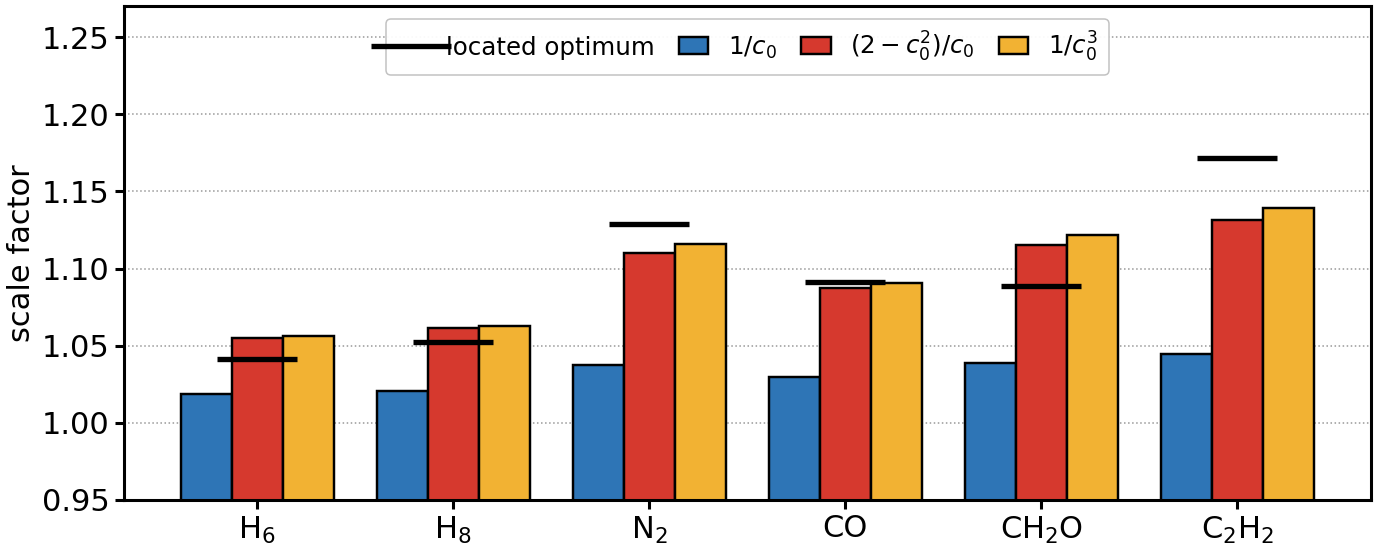

In [13]:
c0 = np.array([T3[s]['c0']    for s in ORDER])
astar = np.array([T3[s]['astar'] for s in ORDER])
forms = [(r'$1/c_0$',         1/c0,             C_BLU),
         (r'$(2-c_0^2)/c_0$', (2 - c0**2)/c0,   C_RED),
         (r'$1/c_0^3$',       1/c0**3,          C_YEL)]

fig, ax = plt.subplots(figsize=(13, 5.5))
x = np.arange(len(ORDER)); w = 0.26
for k, (name, v, col) in enumerate(forms):
    ax.bar(x + (k-1)*w, v, w, label=name, color=col, **BAR)
ax.plot(x, astar, 'k_', ms=52, mew=3.5, label=r'located optimum', zorder=6)
ax.set_xticks(x); ax.set_xticklabels(LBL); ax.set_ylim(0.95, 1.27)
ax.set_ylabel('scale factor')
ax.legend(ncol=4, loc='upper center', framealpha=0.95, fontsize=16,
          handlelength=1.2, columnspacing=1.0)
fig.tight_layout(); fig.savefig(os.path.join(FIGDIR, 'V1_closed_forms.png'))
plt.show()

## Figure V2 - Eq. 2 read as a selection rule

How many selected doubles the condition admits as the two-qubit fidelity
improves, at a tolerance of one per cent.

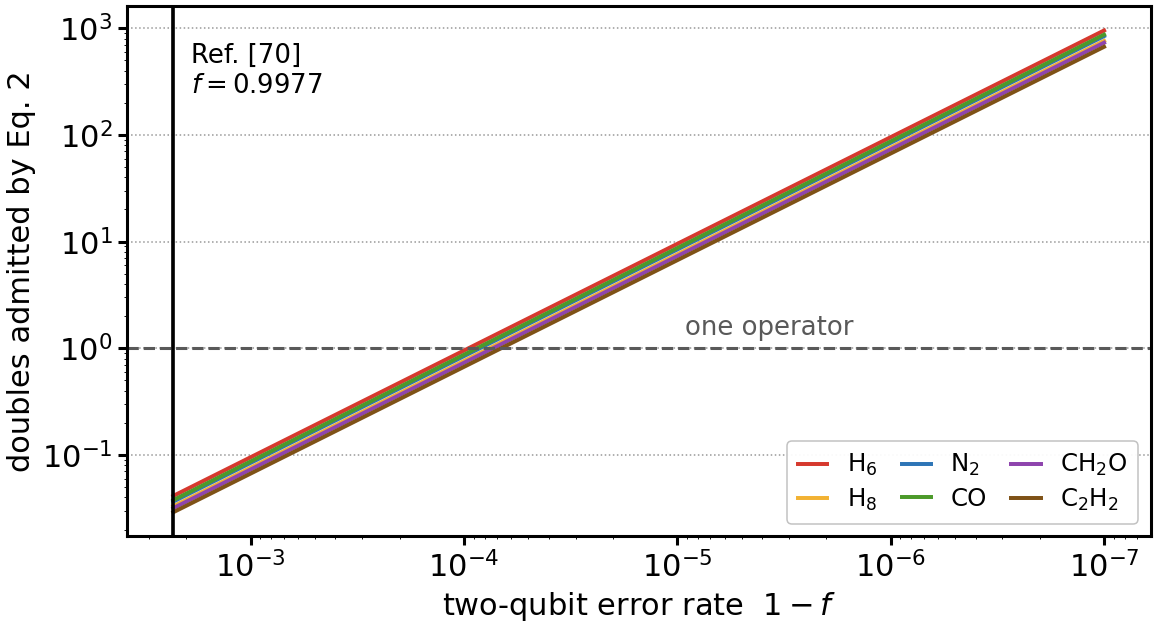

In [14]:
eps = 0.01
f_grid = 1 - np.logspace(np.log10(2.3e-3), np.log10(1e-7), 400)
ncx = np.log(1 - eps) / np.log(f_grid)

fig, ax = plt.subplots(figsize=(11, 6.2))
cols = [C_RED, C_YEL, C_BLU, '#4C9A2A', '#8E44AD', '#7F5217']
for (s, lab, col) in zip(ORDER, LBL, cols):
    cx = T7[s]['cx_per_double']
    ax.plot(1 - f_grid, ncx / cx, lw=2.6, color=col, label=lab)
ax.axhline(1, color='0.35', ls='--', lw=2.0)
ax.axvline(1 - FID, color='black', lw=2.4)
ax.text(1.9e-3, 2.5e2, 'Ref. [70]\n$f=0.9977$', fontsize=17, ha='left')
ax.text(1.5e-6, 1.35, 'one operator', fontsize=17, color='0.35', ha='right')
ax.set_xscale('log'); ax.set_yscale('log'); ax.invert_xaxis()
ax.set_xlabel(r'two-qubit error rate  $1-f$')
ax.set_ylabel('doubles admitted by Eq. 2')
ax.legend(ncol=3, loc='lower right', framealpha=0.95, fontsize=16,
          handlelength=1.2, columnspacing=1.0)
fig.tight_layout(); fig.savefig(os.path.join(FIGDIR, 'V2_eq2_selection_rule.png'))
plt.show()

## Figure V3 - the two independent tests of Eq. 5

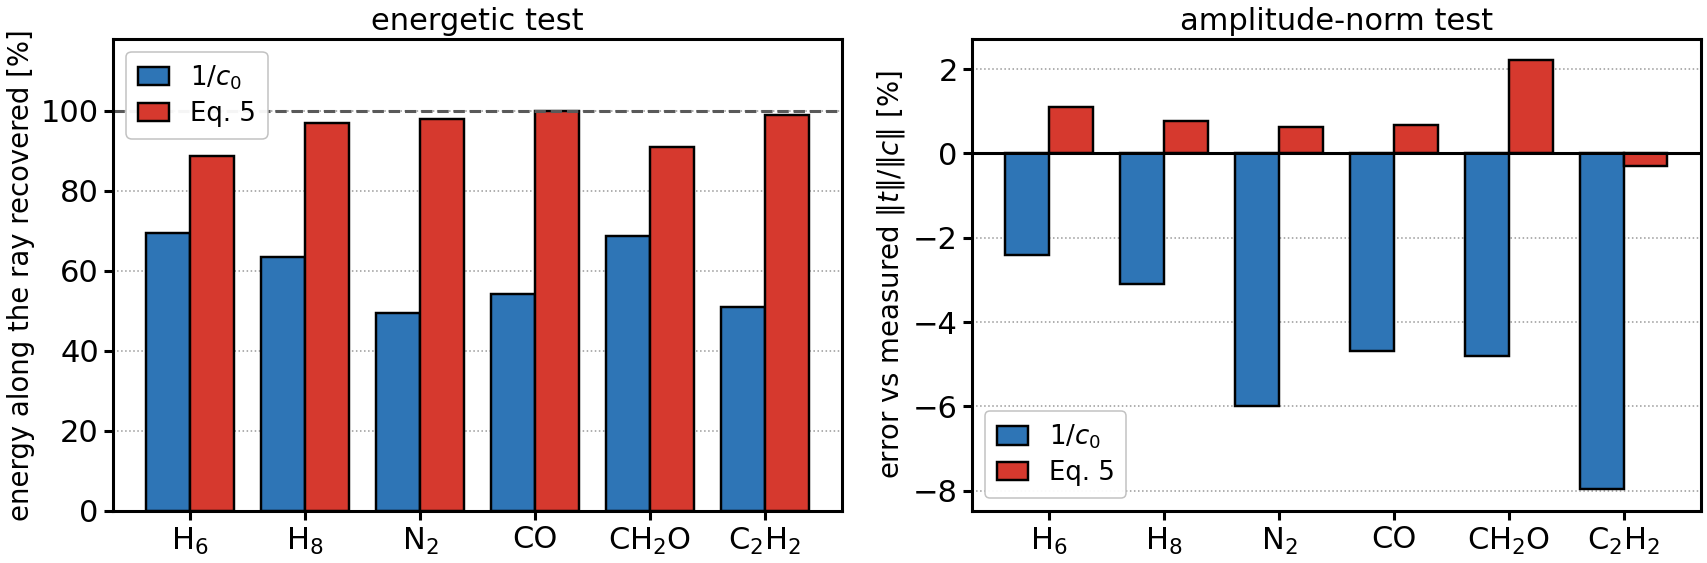

figures written to figures/output/notebook1


In [15]:
rows = {}
for p in sorted(glob.glob(paths.si('comp_*.json'))):
    rows[os.path.basename(p).split('_')[1].split('.')[0]] = json.load(open(p))

f_inv = np.array([T3[s]['f_inv_c0'] for s in ORDER])
f_est = np.array([T3[s]['f_a_est']  for s in ORDER])
e_est = np.array([100*(rows[s]['alpha_est']/rows[s]['norm_ratio'] - 1) for s in ORDER])
e_inv = np.array([100*(rows[s]['inv_c0']  /rows[s]['norm_ratio'] - 1) for s in ORDER])

fig, ax = plt.subplots(1, 2, figsize=(16, 5.6))
x = np.arange(len(ORDER)); w = 0.38
for a, (u, v, ttl, ylab) in zip(ax, [
        (100*f_inv, 100*f_est, 'energetic test',
         'energy along the ray recovered [%]'),
        (e_inv, e_est, 'amplitude-norm test',
         r'error vs measured $\|t\|/\|c\|$ [%]')]):
    a.bar(x - w/2, u, w, label=r'$1/c_0$', color=C_BLU, **BAR)
    a.bar(x + w/2, v, w, label='Eq. 5',    color=C_RED, **BAR)
    a.set_xticks(x); a.set_xticklabels(LBL)
    a.set_ylabel(ylab, fontsize=18); a.set_title(ttl, fontsize=20)
    a.legend(loc='best', framealpha=0.95, fontsize=17, handlelength=1.2)
ax[0].axhline(100, color='0.35', ls='--', lw=2.0); ax[0].set_ylim(0, 118)
ax[1].axhline(0, color='black', lw=2.0)
fig.tight_layout(); fig.savefig(os.path.join(FIGDIR, 'V3_two_tests.png'))
plt.show()
print('figures written to', os.path.relpath(FIGDIR, paths.ROOT))